# Road Severity
**โจทย์:** ถ้าเกิดอุบัติเหตุบนถนนเส้นนี้ ที่หลัก กม. นี้ จะมีโอกาสรุนแรงกี่ %

**รุนแรง** = มีผู้เสียชีวิตหรือผู้บาดเจ็บสาหัสอย่างน้อย 1 คน

notebook นี้: อ่านข้อมูล → คลีน → plot ดูข้อมูล

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["figure.figsize"] = (8, 4)
# รหัสถนนบางเส้นมีตัวอักษรไทย จึงใส่ Tahoma เป็นฟอนต์สำรอง (ถ้าเครื่องไม่มี ให้เปลี่ยนเป็น "Thonburi" หรือ "Sarabun")
plt.rcParams["font.family"] = ["DejaVu Sans", "Tahoma"]

In [2]:
# notebook อยู่ใน notebooks/explore_idea/ จึงย้อนขึ้น 2 ชั้นไปหาโฟลเดอร์ data
raw_dir = "../../data/datagov/"
output_dir = "../../data/explore_idea/road_severity/"

years = [2020, 2021, 2022, 2023, 2024, 2025, 2026]
segment_km = 5          # ตัดถนนเป็นช่วงละ 5 กม.

## 1. อ่านข้อมูล

In [3]:
# ชื่อคอลัมน์ไทย -> อังกฤษ (ปี 2026 ตั้งชื่อต่างจากปีอื่น จึงใส่ไว้ทั้งสองแบบ)
column_names = {
    "วันที่เกิดเหตุ": "date_text",
    "เวลา": "time_text",
    "ACC_CODE": "accident_code",
    "หน่วยงาน": "agency",
    "รหัสสายทาง": "road_code",
    "สายทาง": "road_name",
    "KM": "kilometer",
    "ก.ม.": "kilometer",
    "จังหวัด": "province",
    "สภาพอากาศ": "weather",
    "LATITUDE": "latitude",
    "LONGITUDE": "longitude",
    "รถที่เกิดเหตุ": "vehicle_count",
    "จำนวนรถที่เกิดเหตุ(รวมคันที่1)": "vehicle_count",
    "รถจักรยานยนต์": "motorcycle",
    "รถสามล้อเครื่อง": "tricycle",
    "รถยนต์นั่งส่วนบุคคล": "car",
    "รถยนต์นั่งส่วนบุคคล/รถยนต์นั่งสาธารณะ": "car",
    "รถตู้": "van",
    "รถปิคอัพโดยสาร": "passenger_pickup",
    "รถโดยสารมากกว่า4ล้อ": "bus",
    "รถปิคอัพบรรทุก4ล้อ": "pickup",
    "รถบรรทุก6ล้อ": "truck_6_wheels",
    "รถบรรทุกไม่เกิน10ล้อ": "truck_10_wheels",
    "รถบรรทุกมากกว่า6ล้อไม่เกิน10ล้อ": "truck_10_wheels",
    "รถบรรทุกมากกว่า10ล้อ": "truck_over_10_wheels",
    "รถบรรทุกมากกว่า10ล้อ(รถพ่วง)": "truck_over_10_wheels",
    "รถอีแต๋น": "farm_vehicle",
    "รถอื่นๆ": "other_vehicle",
    "อื่นๆ": "other_vehicle",
    "คนเดินเท้า": "pedestrian",
    "ผู้เสียชีวิต": "deaths",
    "จำนวนผู้เสียชีวิต": "deaths",
    "ผู้บาดเจ็บสาหัส": "serious_injuries",
    "จำนวนผู้บาดเจ็บสาหัส": "serious_injuries",
}

vehicle_types = ["motorcycle", "tricycle", "car", "van", "passenger_pickup", "bus", "pickup",
                 "truck_6_wheels", "truck_10_wheels", "truck_over_10_wheels",
                 "farm_vehicle", "other_vehicle", "pedestrian"]

keep_columns = ["year", "date_text", "time_text", "accident_code", "agency", "road_code", "road_name",
                "kilometer", "province", "weather", "latitude", "longitude", "vehicle_count"]
keep_columns = keep_columns + vehicle_types + ["deaths", "serious_injuries"]

In [4]:
frames = []
for year in years:
    table = pd.read_csv(raw_dir + "accident" + str(year) + ".csv", dtype=str, encoding="utf-8-sig")
    table = table.rename(columns=column_names)
    table["year"] = year
    if year == 2026:
        table["accident_code"] = np.nan     # ไฟล์ปี 2026 ไม่มีรหัสเหตุ
    frames.append(table[keep_columns])
    print(year, ":", len(table), "แถว")

data = pd.concat(frames, ignore_index=True)
print("รวม:", data.shape)
data.head(3)

2020 : 21239 แถว
2021 : 20062 แถว
2022 : 20566 แถว


2023 : 23841 แถว
2024 : 23952 แถว


2025 : 23715 แถว
2026 : 18448 แถว
รวม: (151823, 28)


,year,date_text,time_text,accident_code,agency,road_code,road_name,kilometer,province,weather,...,bus,pickup,truck_6_wheels,truck_10_wheels,truck_over_10_wheels,farm_vehicle,other_vehicle,pedestrian,deaths,serious_injuries
0,2020,1/1/2020,0:05,3785916,กรมทางหลวง,4225,สวนปาล์ม -คลองชี,6.6,กระบี่,แจ่มใส,...,0,0,0,0,0,0,0,1,0,1
1,2020,1/1/2020,0:05,3786314,กรมทางหลวง,3473,หนองจิกรี - ถนนสุด,37,นครสวรรค์,แจ่มใส,...,0,1,0,0,0,0,0,0,0,1
2,2020,1/1/2020,0:15,575019,กรมทางหลวงชนบท,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,7.275,หนองบัวลำภู,แจ่มใส,...,0,0,0,0,0,0,0,0,1,0


## 2. คลีนข้อมูล
หนึ่งเซลล์แก้หนึ่งปัญหา

In [5]:
# 2.1 วันที่: แต่ละปีเขียนไม่เหมือนกัน
for year in years:
    example = data[data["year"] == year].iloc[0]
    print(year, "| วันที่:", example["date_text"], "| เวลา:", example["time_text"])

2020 | วันที่: 1/1/2020 | เวลา: 0:05
2021 | วันที่: 1/1/2021 | เวลา: 0:00
2022 | วันที่: 01/01/2022 | เวลา: 0:01
2023 | วันที่: 1/1/2023 | เวลา: 0:01
2024 | วันที่: 45292 | เวลา: 0.008333333
2025 | วันที่: 45658 | เวลา: 0:00
2026 | วันที่: 1/1/2026 | เวลา: 0:01


In [6]:
data["date"] = pd.NaT

# ปี 2020-2023 เขียนแบบ เดือน/วัน/ปี เช่น 1/31/2020
rows = data["year"] <= 2023
data.loc[rows, "date"] = pd.to_datetime(data.loc[rows, "date_text"], format="%m/%d/%Y", errors="coerce")

# ปี 2024-2025 เป็นเลขลำดับวันของ Excel เช่น 45540 (นับจาก 30 ธ.ค. 1899)
rows = (data["year"] == 2024) | (data["year"] == 2025)
day_numbers = pd.to_numeric(data.loc[rows, "date_text"], errors="coerce")
data.loc[rows, "date"] = pd.to_datetime(day_numbers, unit="D", origin="1899-12-30", errors="coerce")

# ปี 2026 เขียนแบบ วัน/เดือน/ปี เช่น 31/1/2026
rows = data["year"] == 2026
data.loc[rows, "date"] = pd.to_datetime(data.loc[rows, "date_text"], format="%d/%m/%Y", errors="coerce")

data["date"] = pd.to_datetime(data["date"])

# วันที่ต้องอ่านได้ และต้องอยู่ในปีเดียวกับไฟล์
good_date = ~data["date"].isna() & (data["date"].dt.year == data["year"])
print("ลบแถวที่วันที่ใช้ไม่ได้:", (~good_date).sum())
data = data[good_date].copy()

ลบแถวที่วันที่ใช้ไม่ได้: 1


In [7]:
# 2.2 ชั่วโมง: ส่วนใหญ่เขียน "14:30" แต่ปี 2024 เป็นเศษส่วนของวัน เช่น 0.5 = เที่ยงวัน
def time_to_hour(text):
    if pd.isna(text):
        return np.nan
    if ":" in text:
        return int(text.split(":")[0])
    minutes = round(float(text) * 24 * 60)     # ปัดเป็นนาทีก่อน กัน 0.99999 ชั่วโมงกลายเป็น 0
    hour = minutes // 60
    if hour > 23:
        hour = 23
    return hour


data["hour"] = data["time_text"].apply(time_to_hour)
print("ชั่วโมง:", data["hour"].min(), "ถึง", data["hour"].max(), "| ค่าว่าง:", data["hour"].isna().sum())

ชั่วโมง: 0 ถึง 23 | ค่าว่าง: 0


In [8]:
# 2.3 แถวซ้ำ: รหัสเหตุเดียวกันในปีเดียวกัน = เหตุเดียวที่ถูกบันทึกซ้ำ
rows_before = len(data)

has_code = ~data["accident_code"].isna()
repeated = has_code & data.duplicated(subset=["year", "accident_code"])
data = data[~repeated]

# ปี 2026 ไม่มีรหัสเหตุ จึงลบแถวที่เหมือนกันทุกช่องอีกรอบ
data = data.drop_duplicates().copy()

print("ลบแถวซ้ำ:", rows_before - len(data), "| เหลือ:", len(data))

ลบแถวซ้ำ: 1725 | เหลือ: 150097


In [9]:
# 2.4 ตัวเลข และคำตอบ severe
number_columns = ["kilometer", "latitude", "longitude", "vehicle_count", "deaths", "serious_injuries"]
number_columns = number_columns + vehicle_types
for column in number_columns:
    data[column] = pd.to_numeric(data[column], errors="coerce")

# ประเภทรถที่เป็น 0 ทุกแถว ไม่มีข้อมูลให้เรียน จึงตัดทิ้ง
used_vehicle_types = []
for vehicle in vehicle_types:
    if data[vehicle].sum() == 0:
        print("ตัดทิ้ง เพราะเป็น 0 ทุกแถว:", vehicle)
    else:
        used_vehicle_types.append(vehicle)
vehicle_types = used_vehicle_types

# severe = 1 เมื่อมีผู้เสียชีวิตหรือบาดเจ็บสาหัสอย่างน้อย 1 คน
data["severe"] = ((data["deaths"] + data["serious_injuries"]) > 0).astype(int)
print("ค่าว่างของคอลัมน์ตัวเลข:", data[number_columns].isna().sum().sum())
print("severe:", round(data["severe"].mean() * 100, 1), "%")

ตัดทิ้ง เพราะเป็น 0 ทุกแถว: bus
ตัดทิ้ง เพราะเป็น 0 ทุกแถว: farm_vehicle
ค่าว่างของคอลัมน์ตัวเลข: 2831
severe: 18.5 %


In [10]:
# 2.5 เส้นถนน + หลัก กม.: เป็นสิ่งที่ใช้ทำนาย แถวที่ไม่มีจึงใช้ไม่ได้
data["road_code"] = data["road_code"].str.strip()
has_road = ~data["road_code"].isna() & ~data["kilometer"].isna()
print("ลบแถวที่ไม่มีเส้นถนนหรือ กม.:", (~has_road).sum())
data = data[has_road].copy()

# ตัดเป็นช่วงละ 5 กม. เช่น ถนน 4225 กม. 12.3 อยู่ช่วง "4225 km 10-15"
segment_start = (data["kilometer"] // segment_km * segment_km).astype(int)
segment_end = segment_start + segment_km
data["road_segment"] = data["road_code"] + " km " + segment_start.astype(str) + "-" + segment_end.astype(str)

# บางปีไม่มีชื่อถนน จึงใช้ชื่อที่เคยบันทึกไว้ของช่วงเดียวกัน
# (ชื่อในข้อมูลเป็นชื่อตอน เช่น ถนน 4 มีหลายชื่อตามจังหวัด จึงเติมตามช่วง ไม่ใช่ตามรหัสถนน)
name_of_segment = data.groupby("road_segment")["road_name"].first()
data["road_name"] = data["road_segment"].map(name_of_segment)

print("เส้นถนน:", data["road_code"].nunique(), "เส้น | ช่วงถนน:", data["road_segment"].nunique(), "ช่วง")
data[["road_code", "road_name", "kilometer", "road_segment"]].head(3)

ลบแถวที่ไม่มีเส้นถนนหรือ กม.: 1107
เส้นถนน: 2977 เส้น | ช่วงถนน: 12450 ช่วง


,road_code,road_name,kilometer,road_segment
0,4225,สวนปาล์ม -คลองชี,6.600,4225 km 5-10
1,3473,หนองจิกรี - ถนนสุด,37.000,3473 km 35-40
2,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,7.275,นภ.3038 km 5-10


In [11]:
# 2.6 พิกัด: นอกกรอบประเทศไทยถือว่ากรอกผิด ทำเป็นค่าว่าง (ยังเก็บแถวไว้ เพราะพิกัดใช้แค่วาดแผนที่)
in_thailand = (data["latitude"] >= 5.5) & (data["latitude"] <= 20.6) & (data["longitude"] >= 97.2) & (data["longitude"] <= 105.8)
data.loc[~in_thailand, "latitude"] = np.nan
data.loc[~in_thailand, "longitude"] = np.nan
print("พิกัดที่ใช้ไม่ได้:", (~in_thailand).sum())

พิกัดที่ใช้ไม่ได้: 214


In [12]:
# 2.7 ข้อความ: แปลงเป็นภาษาอังกฤษ ให้กราฟอ่านได้ทุกเครื่อง
road_types = {
    "กรมทางหลวง": "highway",
    "กรมทางหลวงชนบท": "rural road",
    "การทางพิเศษแห่งประเทศไทย": "expressway",
}
# สภาพอากาศแบบอื่น (หมอก มืดครึ้ม พายุ ไม่ระบุ) รวมกันมีไม่ถึง 2% จึงรวมเป็น other
weathers = {
    "แจ่มใส": "clear",
    "ฝนตก": "rain",
}
data["road_type"] = data["agency"].str.strip().map(road_types)
data["weather"] = data["weather"].str.strip().map(weathers).fillna("other")

# "อยุธยา" กับ "พระนครศรีอยุธยา" คือจังหวัดเดียวกัน
data["province"] = data["province"].str.strip().replace({"อยุธยา": "พระนครศรีอยุธยา"})

print(data["road_type"].value_counts())
print(data["weather"].value_counts())

road_type
highway       140190
rural road      6835
expressway      1965
Name: count, dtype: int64
weather
clear    128818
rain      18223
other      1949
Name: count, dtype: int64


In [13]:
# 2.8 บันทึก: หนึ่งแถว = อุบัติเหตุ 1 ครั้ง
clean_columns = ["year", "date", "hour", "road_type", "road_code", "road_name", "kilometer", "road_segment",
                 "province", "latitude", "longitude", "weather", "vehicle_count"]
clean_columns = clean_columns + vehicle_types + ["deaths", "serious_injuries", "severe"]

clean = data[clean_columns].reset_index(drop=True)
clean.to_csv(output_dir + "clean/road_accidents_clean.csv", index=False, encoding="utf-8-sig")
print("บันทึกแล้ว:", clean.shape)
clean.head(3)

บันทึกแล้ว: (148990, 27)


,year,date,hour,road_type,road_code,road_name,kilometer,road_segment,province,latitude,...,passenger_pickup,pickup,truck_6_wheels,truck_10_wheels,truck_over_10_wheels,other_vehicle,pedestrian,deaths,serious_injuries,severe
0,2020,2020-01-01,0,highway,4225,สวนปาล์ม -คลองชี,6.600,4225 km 5-10,กระบี่,8.008887,...,0,0,0,0,0,0,1,0,1,1
1,2020,2020-01-01,0,highway,3473,หนองจิกรี - ถนนสุด,37.000,3473 km 35-40,นครสวรรค์,15.650940,...,0,1,0,0,0,0,0,0,1,1
2,2020,2020-01-01,0,rural road,นภ.3038,ถนนผังเมืองรวมเมืองหนองบัวลำภู สาย ข,7.275,นภ.3038 km 5-10,หนองบัวลำภู,17.191475,...,0,0,0,0,0,0,0,1,0,1


## 3. Plot ดูข้อมูล
ดูคำตอบ (severe) ก่อน แล้วดูทีละ X ที่จะใช้ทำนาย: เวลา ประเภทรถ อากาศ เส้นถนน

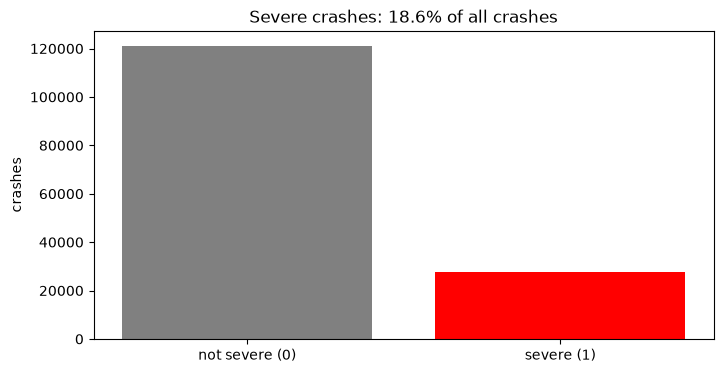

In [14]:
# 3.1 คำตอบ: รุนแรงกี่ % ของเหตุทั้งหมด
overall_percent = clean["severe"].mean() * 100
severe_counts = clean["severe"].value_counts().sort_index()

plt.bar(["not severe (0)", "severe (1)"], severe_counts.values, color=["grey", "red"])
plt.title("Severe crashes: " + str(round(overall_percent, 1)) + "% of all crashes")
plt.ylabel("crashes")
plt.show()

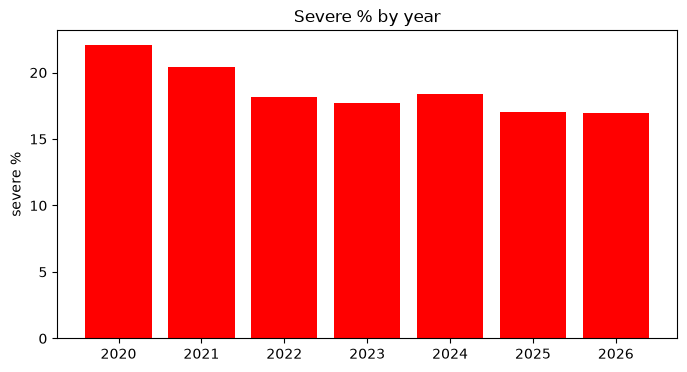

year
2020    22.1
2021    20.4
2022    18.2
2023    17.7
2024    18.4
2025    17.0
2026    16.9
Name: severe, dtype: float64


In [15]:
# 3.2 คำตอบ: % รุนแรงของแต่ละปี
percent_by_year = clean.groupby("year")["severe"].mean() * 100

plt.bar(percent_by_year.index, percent_by_year.values, color="red")
plt.title("Severe % by year")
plt.ylabel("severe %")
plt.show()
print(percent_by_year.round(1))

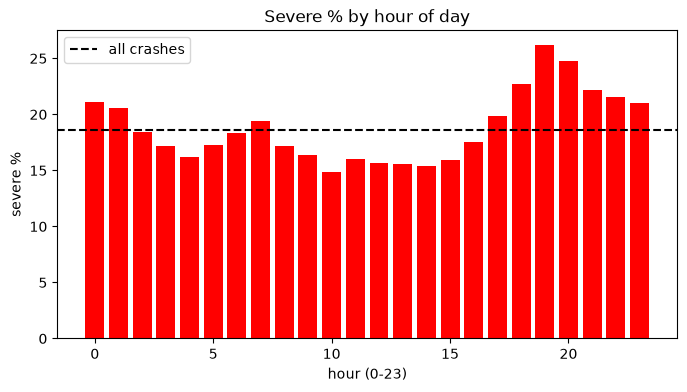

In [16]:
# 3.3 เวลา: % รุนแรงของแต่ละชั่วโมง
percent_by_hour = clean.groupby("hour")["severe"].mean() * 100

plt.bar(percent_by_hour.index, percent_by_hour.values, color="red")
plt.axhline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.title("Severe % by hour of day")
plt.xlabel("hour (0-23)")
plt.ylabel("severe %")
plt.legend()
plt.show()

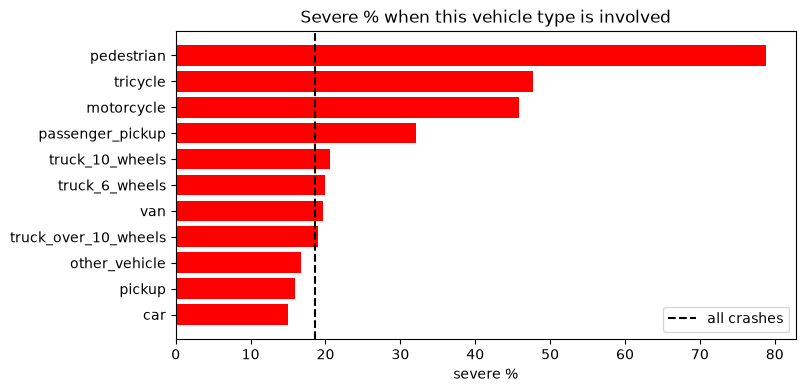

,vehicle,crashes,severe_percent
10,pedestrian,1537,78.9
1,tricycle,1041,47.6
0,motorcycle,32102,45.9
4,passenger_pickup,843,32.1
7,truck_10_wheels,6516,20.7
6,truck_6_wheels,8600,19.9
3,van,3548,19.7
8,truck_over_10_wheels,16655,19.0
9,other_vehicle,9504,16.7
5,pickup,69352,15.9


In [17]:
# 3.4 ประเภทรถ: ถ้ามีรถประเภทนี้อยู่ในเหตุ รุนแรงกี่ %
rows = []
for vehicle in vehicle_types:
    involved = clean[clean[vehicle] > 0]
    rows.append({"vehicle": vehicle, "crashes": len(involved), "severe_percent": involved["severe"].mean() * 100})

vehicle_table = pd.DataFrame(rows).sort_values("severe_percent")

plt.barh(vehicle_table["vehicle"], vehicle_table["severe_percent"], color="red")
plt.axvline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.title("Severe % when this vehicle type is involved")
plt.xlabel("severe %")
plt.legend()
plt.show()
vehicle_table.sort_values("severe_percent", ascending=False).round(1)

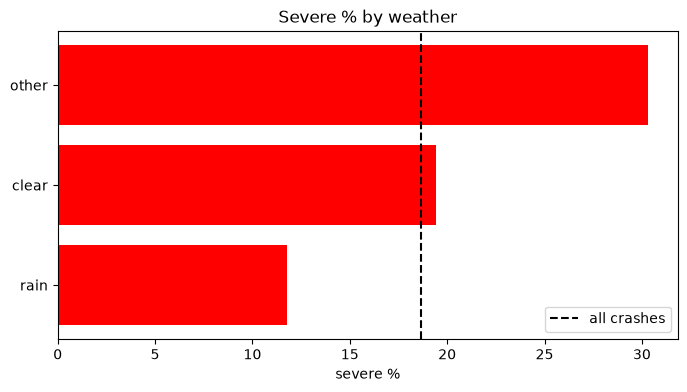

,crashes,severe_rate
weather,,
rain,18223,0.118
clear,128818,0.194
other,1949,0.303


In [18]:
# 3.5 อากาศ: % รุนแรงของแต่ละสภาพอากาศ
weather_table = clean.groupby("weather")["severe"].agg(["count", "mean"])
weather_table.columns = ["crashes", "severe_rate"]
weather_table = weather_table.sort_values("severe_rate")

plt.barh(weather_table.index, weather_table["severe_rate"] * 100, color="red")
plt.axvline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.title("Severe % by weather")
plt.xlabel("severe %")
plt.legend()
plt.show()
weather_table.round(3)

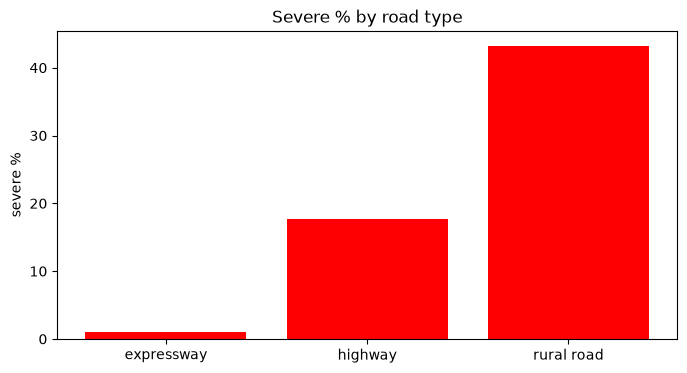

,crashes,severe_rate
road_type,,
expressway,1965,0.010
highway,140190,0.177
rural road,6835,0.433


In [19]:
# 3.6 เส้นถนน: % รุนแรงของแต่ละประเภทถนน
road_type_table = clean.groupby("road_type")["severe"].agg(["count", "mean"])
road_type_table.columns = ["crashes", "severe_rate"]

plt.bar(road_type_table.index, road_type_table["severe_rate"] * 100, color="red")
plt.title("Severe % by road type")
plt.ylabel("severe %")
plt.show()
road_type_table.round(3)

ช่วงถนนที่มีเหตุตั้งแต่ 30 ครั้ง: 1111 จาก 12450 ช่วง


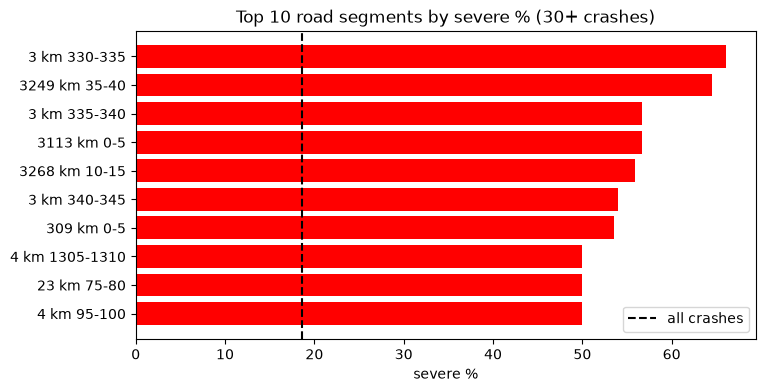

,crashes,severe_rate,road_name,province
road_segment,,,,
3 km 330-335,59,0.661,โพธิ์ทอง - บ้านพลิ้ว,จันทบุรี
3249 km 35-40,31,0.645,เขาไร่ยา - แพร่งขาหยั่ง,จันทบุรี
3 km 335-340,67,0.567,โพธิ์ทอง - บ้านพลิ้ว,จันทบุรี
3113 km 0-5,30,0.567,สำโรง - สะพานภูมิพล,สมุทรปราการ
3268 km 10-15,34,0.559,บางพลี - บางบ่อ,สมุทรปราการ
3 km 340-345,63,0.540,โพธิ์ทอง - บ้านพลิ้ว,จันทบุรี
309 km 0-5,56,0.536,วังน้อย - ทางแยกต่างระดับอยุธยา,พระนครศรีอยุธยา
4 km 1305-1310,34,0.500,พังลา - จุดผ่านแดนถาวรสะเดา (เขตแดนไทย/มาเลเซีย),สงขลา
23 km 75-80,36,0.500,หนองจิก - ห้วยแอ่ง,มหาสารคาม


In [20]:
# 3.7 เส้นถนน: ช่วงถนน 5 กม. ที่ถ้าเกิดเหตุแล้วรุนแรงบ่อยที่สุด 10 อันดับ
min_segment_crashes = 30    # ช่วงที่มีเหตุน้อยกว่านี้ % จะแกว่ง จึงไม่จัดอันดับ

segment_table = clean.groupby("road_segment")["severe"].agg(["count", "mean"])
segment_table.columns = ["crashes", "severe_rate"]
segment_table["road_name"] = clean.groupby("road_segment")["road_name"].first()
segment_table["province"] = clean.groupby("road_segment")["province"].first()

busy_segments = segment_table[segment_table["crashes"] >= min_segment_crashes]
top_segments = busy_segments.sort_values("severe_rate", ascending=False).head(10)
print("ช่วงถนนที่มีเหตุตั้งแต่", min_segment_crashes, "ครั้ง:", len(busy_segments), "จาก", len(segment_table), "ช่วง")

plt.barh(top_segments.index, top_segments["severe_rate"] * 100, color="red")
plt.axvline(overall_percent, color="black", linestyle="--", label="all crashes")
plt.gca().invert_yaxis()
plt.title("Top 10 road segments by severe % (" + str(min_segment_crashes) + "+ crashes)")
plt.xlabel("severe %")
plt.legend()
plt.show()
top_segments.round(3)

เหตุปี 2024-2026 ที่อยู่บนช่วงถนนที่มีประวัติพอ: 42054 จาก 65472


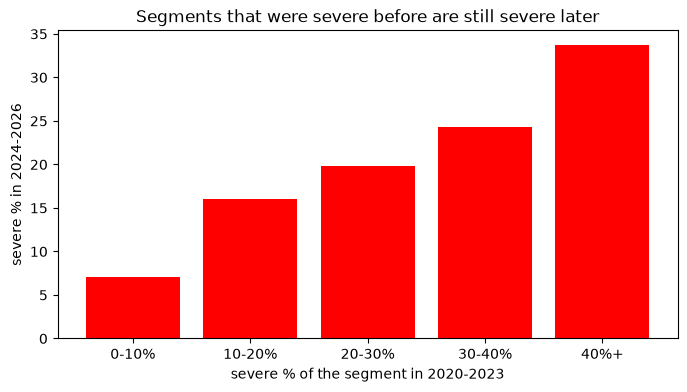

,future_crashes,future_severe_rate
past_band,,
0-10%,20219,0.071
10-20%,9346,0.161
20-30%,6591,0.198
30-40%,3664,0.243
40%+,2234,0.337


In [21]:
# 3.8 เส้นถนน: ช่วงถนนที่เคยรุนแรงในอดีต (2020-2023) ยังรุนแรงในปีหลัง (2024-2026) ไหม
min_past_crashes = 10       # ใช้เฉพาะช่วงที่มีเหตุในอดีตพอให้นับ

past = clean[clean["year"] <= 2023]
future = clean[clean["year"] >= 2024].copy()

past_table = past.groupby("road_segment")["severe"].agg(["count", "mean"])
past_table.columns = ["past_crashes", "past_severe_rate"]
past_table = past_table[past_table["past_crashes"] >= min_past_crashes]


def to_band(rate):
    if rate < 0.10:
        return "0-10%"
    if rate < 0.20:
        return "10-20%"
    if rate < 0.30:
        return "20-30%"
    if rate < 0.40:
        return "30-40%"
    return "40%+"


past_table["past_band"] = past_table["past_severe_rate"].apply(to_band)
future["past_band"] = future["road_segment"].map(past_table["past_band"])

band_table = future.groupby("past_band")["severe"].agg(["count", "mean"])
band_table.columns = ["future_crashes", "future_severe_rate"]
print("เหตุปี 2024-2026 ที่อยู่บนช่วงถนนที่มีประวัติพอ:", band_table["future_crashes"].sum(), "จาก", len(future))

plt.bar(band_table.index, band_table["future_severe_rate"] * 100, color="red")
plt.title("Segments that were severe before are still severe later")
plt.xlabel("severe % of the segment in 2020-2023")
plt.ylabel("severe % in 2024-2026")
plt.show()
band_table.round(3)

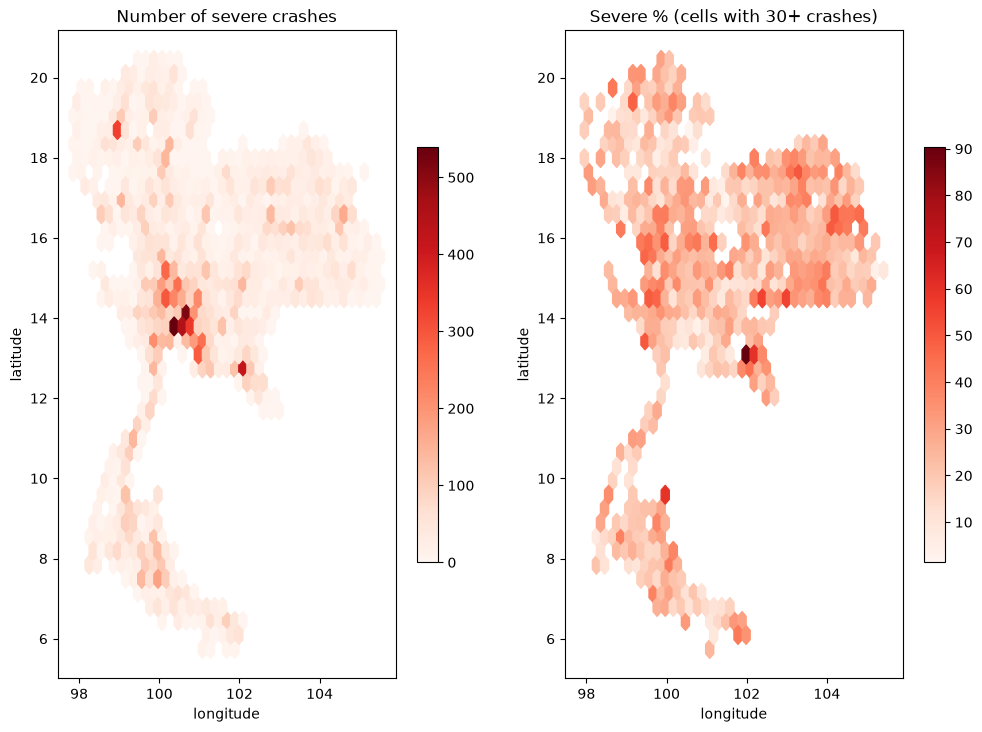

In [22]:
# 3.9 แผนที่: แบ่งเป็นช่องหกเหลี่ยม 38 ช่องตามแนวกว้าง แล้วระบายสีตามเหตุรุนแรง
grid_size = 38
min_cell_crashes = 30       # ช่องที่มีเหตุน้อยกว่านี้ % จะแกว่ง จึงไม่แสดงในแผนที่ขวา

map_data = clean.dropna(subset=["latitude", "longitude"])
fig, axes = plt.subplots(1, 2, figsize=(12, 9))

left = axes[0].hexbin(map_data["longitude"], map_data["latitude"], C=map_data["severe"],
                      reduce_C_function=np.sum, gridsize=grid_size, mincnt=1, cmap="Reds")
axes[0].set_title("Number of severe crashes")
fig.colorbar(left, ax=axes[0], shrink=0.6)

right = axes[1].hexbin(map_data["longitude"], map_data["latitude"], C=map_data["severe"] * 100,
                       reduce_C_function=np.mean, gridsize=grid_size, mincnt=min_cell_crashes, cmap="Reds")
axes[1].set_title("Severe % (cells with " + str(min_cell_crashes) + "+ crashes)")
fig.colorbar(right, ax=axes[1], shrink=0.6)

for ax in axes:
    ax.set_xlabel("longitude")
    ax.set_ylabel("latitude")
    ax.set_aspect("equal")
plt.show()

## สรุป
- **ข้อมูลหลังคลีน:** 148,990 เหตุ บนถนน 2,977 เส้น แบ่งเป็น 12,450 ช่วง (ช่วงละ 5 กม.)
- **คำตอบ:** รุนแรง 18.6% และลดลงจาก 22.1% (2020) เหลือ 16.9% (2026)
- **เวลา:** กลางคืนรุนแรงกว่า สูงสุดตอน 19 นาฬิกา (26.2%) ต่ำสุดตอน 10 นาฬิกา (14.8%)
- **ประเภทรถ:** มีคนเดินเท้า 78.9% สามล้อ 47.6% จักรยานยนต์ 45.9% ส่วนรถยนต์ 14.9%
- **อากาศ:** ฝนตกรุนแรงน้อยกว่าอากาศแจ่มใส (11.8% กับ 19.4%)
- **เส้นถนน:** ช่วงที่เคยรุนแรงเกิน 40% ในปี 2020-2023 ยังรุนแรง 33.7% ในปี 2024-2026 ส่วนช่วงที่เคยต่ำกว่า 10% เหลือ 7.1% แปลว่าเส้นถนน + กม. ใช้ทำนายได้
- **ระวัง:** ทางพิเศษรุนแรง 1.0% แต่ทางหลวงชนบท 43.3% ส่วนหนึ่งอาจมาจากวิธีบันทึกที่ต่างกัน ไม่ใช่ความอันตรายของถนนอย่างเดียว